Importing Essential Libraries

In [33]:
from itertools import accumulate
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from sklearn.model_selection import GridSearchCV

import joblib

Loading DataSet

In [2]:
data = pd.read_csv('Student_Depression_Dataset.csv')
print(f'Rows : {data.shape[0]}\nColumns : {data.shape[1]}')

Rows : 4464
Columns : 13


Studying Data

In [3]:
data.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [5]:
data.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [6]:
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


EDA

In [7]:
Numerical_columns = data.select_dtypes(['int64', 'float64'])
Categorical_columns = data.drop(columns = Numerical_columns)

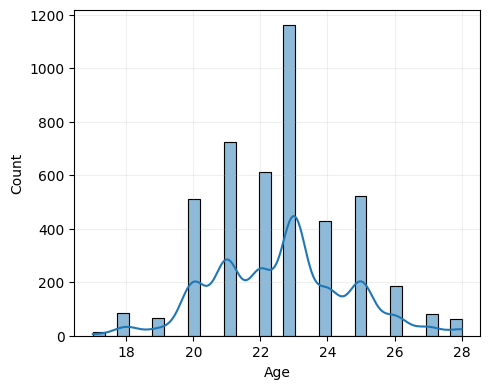

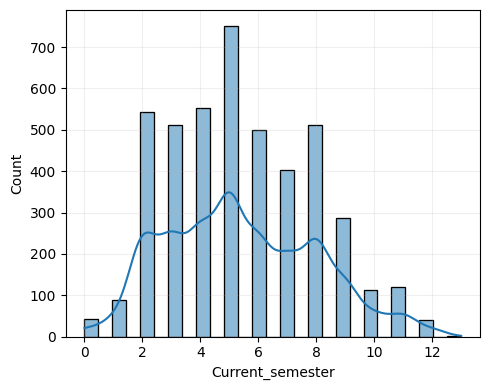

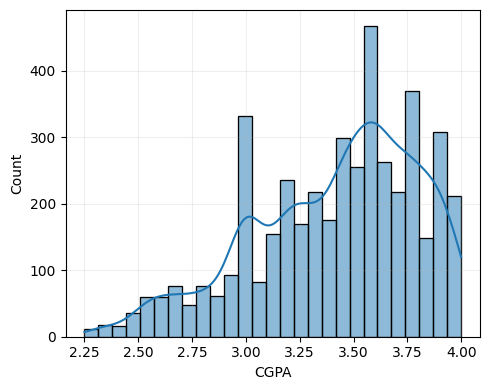

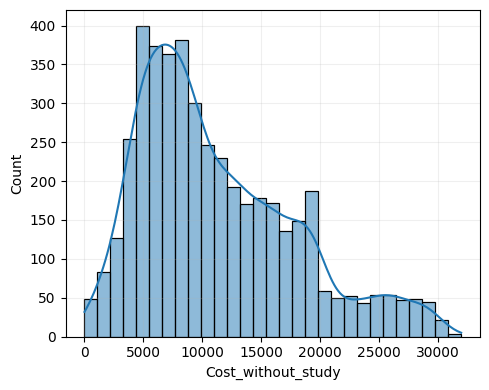

In [8]:
for columns in Numerical_columns:
  plt.figure(figsize = (5, 4))
  sns.histplot(data[columns], kde = True)
  plt.tight_layout()
  plt.grid(True, alpha = 0.2)
  plt.show()

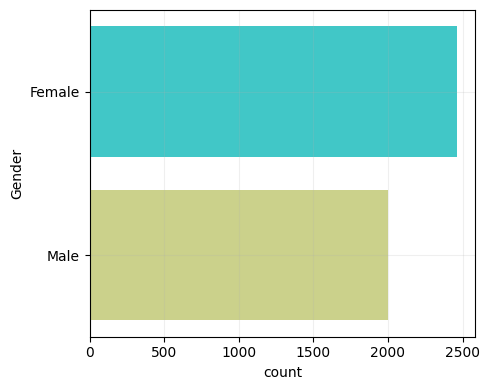

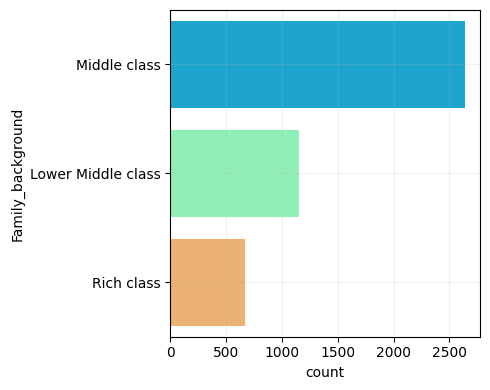

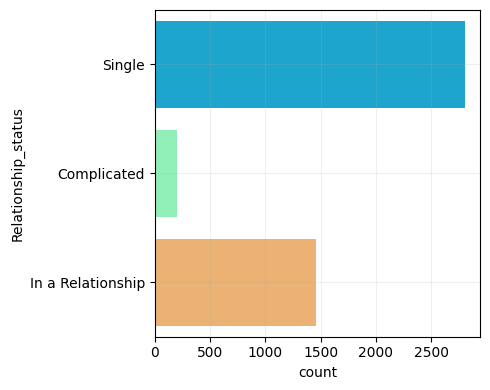

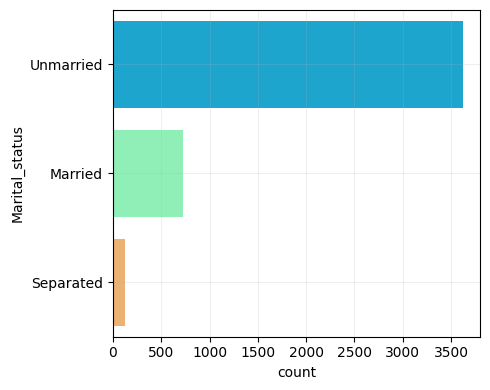

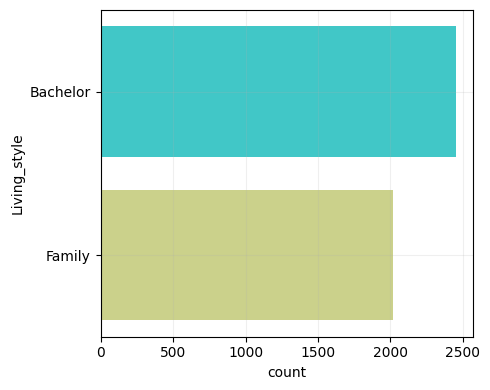

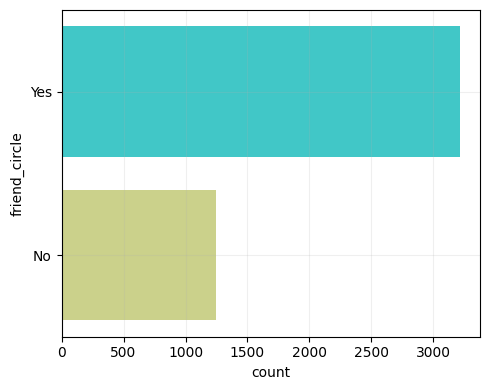

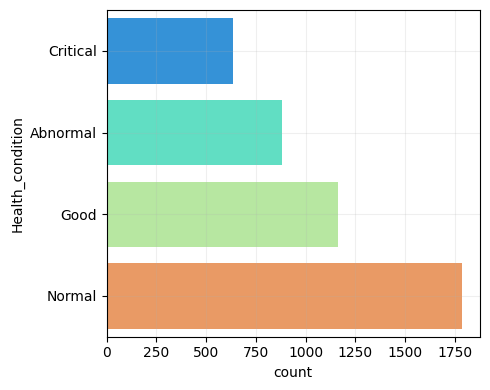

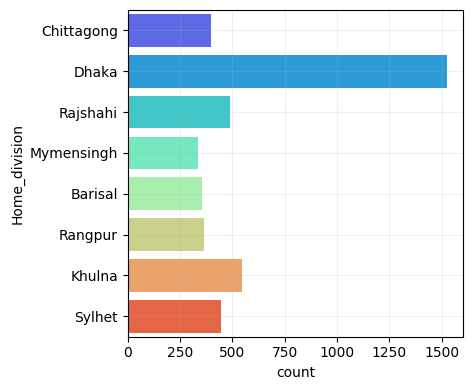

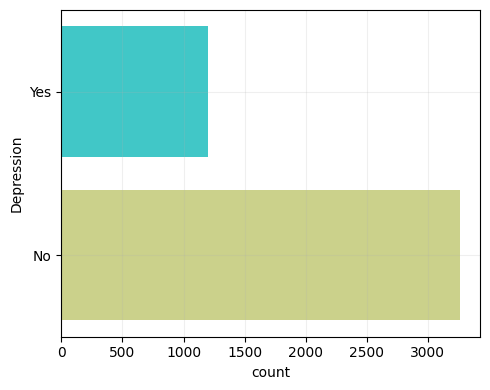

In [9]:
for columns in Categorical_columns:
  plt.figure(figsize = (5, 4))
  sns.countplot(data[columns], palette = 'rainbow')
  plt.tight_layout()
  plt.grid(True, alpha = 0.2)
  plt.show()

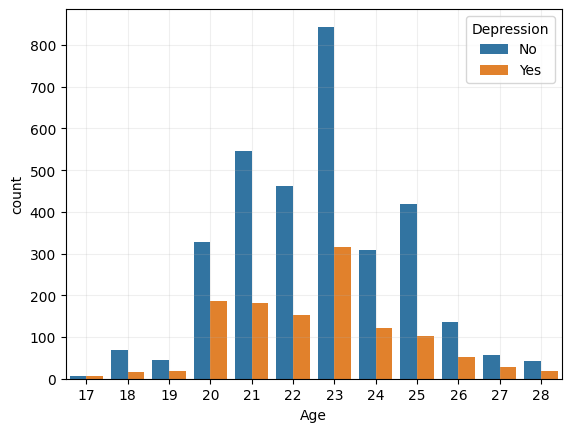

In [10]:
sns.countplot(data = data, x = 'Age', hue = 'Depression')
plt.grid(True, alpha = 0.2)

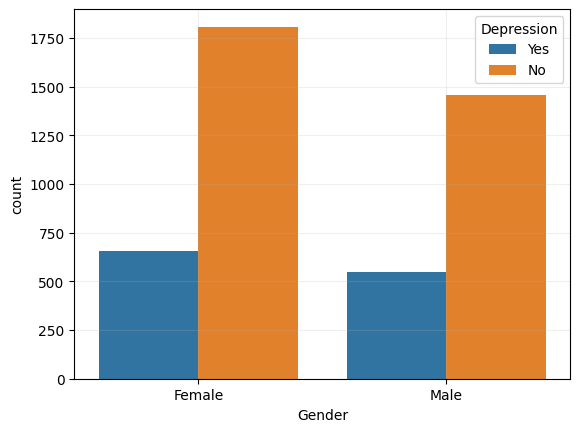

In [11]:
sns.countplot(data = data, x = 'Gender', hue = 'Depression')
plt.grid(True, alpha = 0.2)

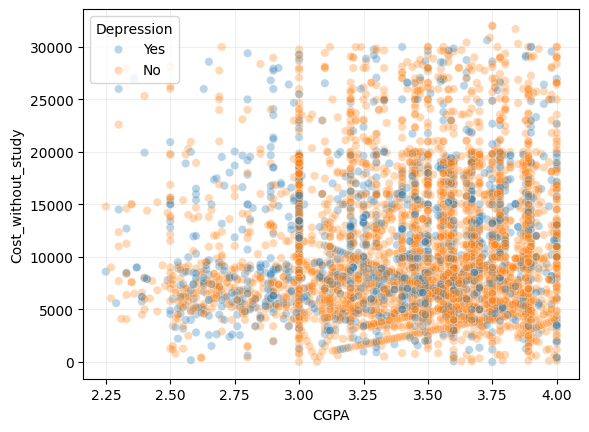

In [12]:
sns.scatterplot(data = data, x = 'CGPA', y = 'Cost_without_study', alpha = 0.3, hue = 'Depression')
plt.grid(True, alpha = 0.2)

Preprocessing

In [13]:
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [14]:

binary_mapping = {
    'Gender': {'Male': 1, 'Female': 0},
    'Living_style': {'Family': 1, 'Bachelor': 0},
    'friend_circle': {'Yes': 1, 'No': 0},
    'Depression': {'Yes': 1, 'No': 0}
}

for col, mapping in binary_mapping.items():
    data[col] = data[col].map(mapping)



data['Family_background'] = data['Family_background'].map({
    'Lower Middle class': 0,
    'Middle class': 1,
    'Rich class': 2
})

In [15]:
categorical_columns = [
    'Relationship_status',
    'Marital_status',
    'Health_condition',
    'Home_division'
]

data = pd.get_dummies(
    data,
    columns=categorical_columns,
    dtype=int
)

In [16]:
data.head()

,Gender,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Cost_without_study,Depression,Relationship_status_Complicated,...,Health_condition_Good,Health_condition_Normal,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,0,22,1,0,8,3.43,1,10113,1,0,...,0,0,0,1,0,0,0,0,0,0
1,1,19,1,0,2,3.70,1,13815,1,0,...,0,0,0,1,0,0,0,0,0,0
2,1,23,1,1,8,3.28,0,15450,1,0,...,0,0,0,0,1,0,0,0,0,0
3,1,20,1,1,2,3.77,0,17413,0,1,...,1,0,0,0,1,0,0,0,0,0
4,0,21,1,1,1,4.00,0,16693,1,0,...,0,0,0,0,1,0,0,0,0,0


Splitting The DataSet

In [17]:
X = data.drop(columns = 'Depression')
y = data['Depression']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

Creating Models Using Pipelines

In [18]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression())
    ]),

    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier())
    ]),

    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC())
    ]),

    'Gaussian NB': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),

    'Decision Tree': DecisionTreeClassifier(),

    'Random Forest': RandomForestClassifier(
        random_state=42
    )
}

Name : Logistic Regression


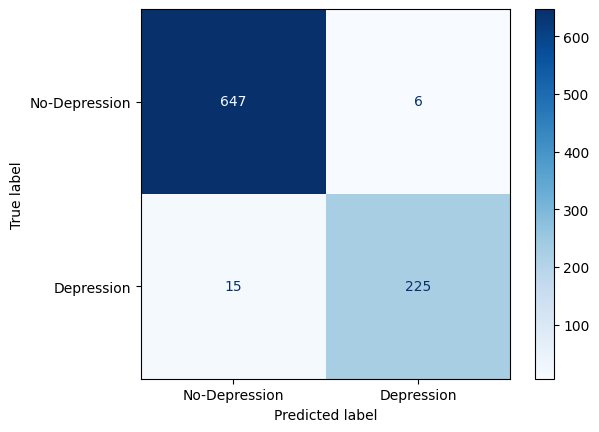

Name : KNN


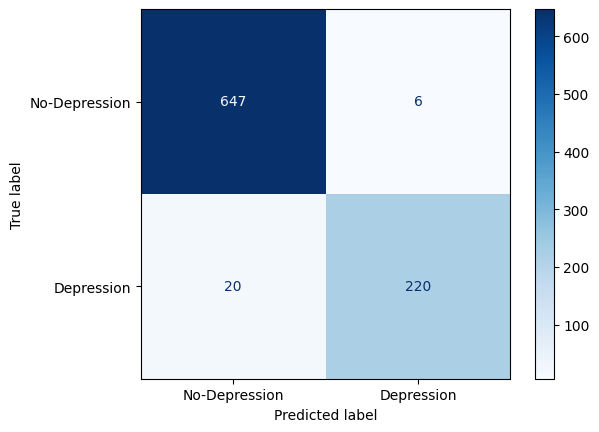

Name : SVM


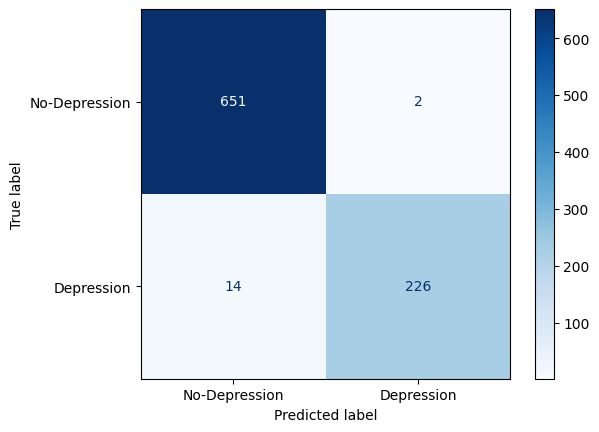

Name : Gaussian NB


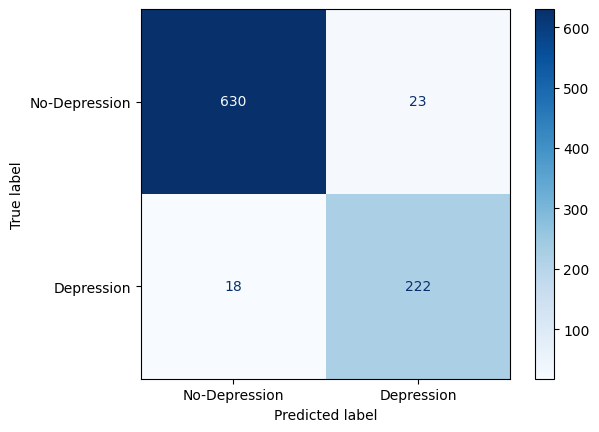

Name : Decision Tree


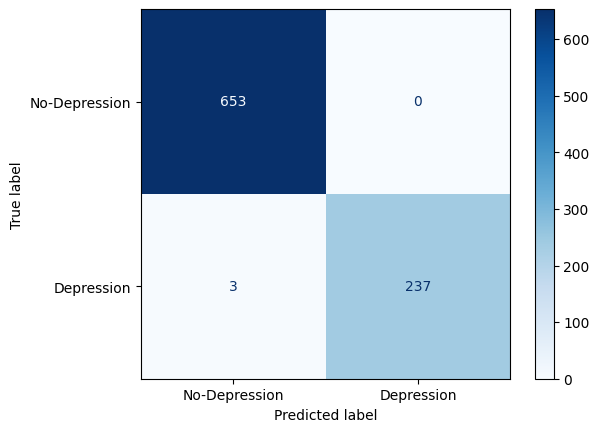

Name : Random Forest


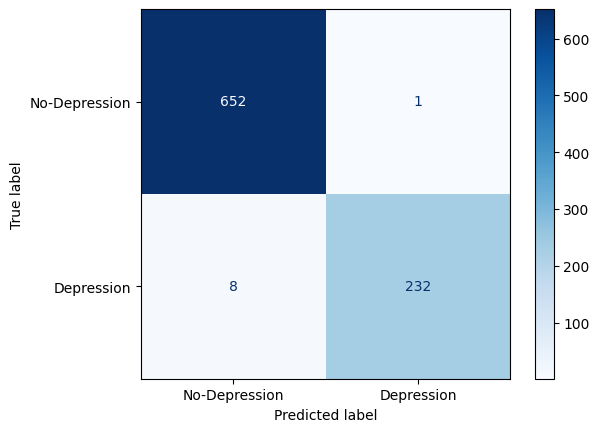

In [19]:
Results = []

for name, model in models.items():
  model.fit(X_train, y_train)
  Predictions = model.predict(X_test)
  print(f'Name : {name}')

  ConfusionMatrix = confusion_matrix(y_test, Predictions)

  Display = ConfusionMatrixDisplay(
    confusion_matrix= ConfusionMatrix,
    display_labels=['No-Depression', 'Depression']
  )

  Display.plot(cmap='Blues')
  plt.show()

  Results.append({
      'Model' : name,
      'Accuracy' : accuracy_score(y_test, Predictions),
      'Precision' : precision_score(y_test, Predictions, zero_division = 0),
      'Recall' : recall_score(y_test, Predictions, zero_division = 0),
      'F1 Score' : f1_score(y_test, Predictions, zero_division = 0)
  })


In [20]:
Results_DataFrame = pd.DataFrame(Results)
Results_DataFrame.sort_values(
    by = 'F1 Score',
    ascending = False
)

,Model,Accuracy,Precision,Recall,F1 Score
4,Decision Tree,0.996641,1.000000,0.987500,0.993711
5,Random Forest,0.989922,0.995708,0.966667,0.980973
2,SVM,0.982083,0.991228,0.941667,0.965812
0,Logistic Regression,0.976484,0.974026,0.937500,0.955414
1,KNN,0.970885,0.973451,0.916667,0.944206
3,Gaussian NB,0.954087,0.906122,0.925000,0.915464


Hyperparameter Tuning


In [21]:
Parameters = {
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [None, 3, 5, 8, 12, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": [0.0, 0.0005, 0.001, 0.01]
}

In [24]:
GridSearch = GridSearchCV(
    estimator = DecisionTreeClassifier(),
    param_grid = Parameters,
    cv = 5,
    scoring = 'f1_weighted',
    n_jobs=-1,
    refit=True,
)

GridSearch.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'ccp_alpha': [0.0, 0.0005, 0.001, 0.01],
                         'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [None, 3, 5, 8, 12, 20],
                         'max_features': [None, 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 5, 10],
                         'min_samples_split': [2, 5, 10, 20],
                         'splitter': ['best', 'random']},
             scoring='f1_weighted')

In [25]:
GridSearch.best_params_

{'ccp_alpha': 0.0,
 'criterion': 'entropy',
 'max_depth': None,
 'max_features': None,
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'splitter': 'best'}

Best CV F1:  0.9938
Train F1:    0.9989
Test F1:     0.9978

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       653
           1       1.00      0.99      1.00       240

    accuracy                           1.00       893
   macro avg       1.00      1.00      1.00       893
weighted avg       1.00      1.00      1.00       893



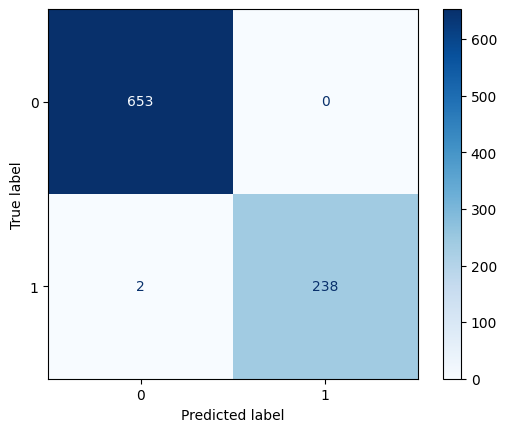

In [32]:

Best_DecisionTree = GridSearch.best_estimator_

train_f1 = f1_score(y_train, Best_DecisionTree.predict(X_train), average="weighted")
test_f1 = f1_score(y_test, Best_DecisionTree.predict(X_test), average="weighted")

print(f"Best CV F1:  {GridSearch.best_score_:.4f}")
print(f"Train F1:    {train_f1:.4f}")
print(f"Test F1:     {test_f1:.4f}\n")
print(classification_report(y_test, Best_DecisionTree.predict(X_test)))

ConfusionMatrixDisplay.from_estimator(Best_DecisionTree, X_test, y_test, cmap='Blues')
plt.show()

Saving The Model

In [34]:
joblib.dump(best_dt, "depression_dt_model.pkl")
joblib.dump(list(X_train.columns), "model_columns.pkl")

['model_columns.pkl']